<a href="https://colab.research.google.com/github/anshuman-dataverse/text-to-image-generation/blob/main/notebooks/milestone2_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 2: Baseline Generation and Parameter Experiments

| Exp. | Script | Setting varied | Images |
|---|---|---|---|
| 1 | `01_baseline.py` | none (SD v1.5, DDIM, 30 steps, w = 7.5), 200 COCO captions | 200 |
| 2 | `02_guidance_sweep.py` | guidance w ∈ {1, 3, 5, 7.5, 10, 15}, 32 captions × 2 seeds | 384 |
| 3 | `03_scheduler_sweep.py` | DDIM, DDPM, PNDM, Euler, Euler-a, DPM++ × {10, 25, 50} steps, 24 captions | 432 |
| 4 | `04_noise_schedule.py` | Euler with leading, linspace, trailing, Karras spacing × {10, 25} steps, plus a 50-step reference, 24 captions | 216 |

Captions come from the Milestone 1 pair manifest. Caption *i* uses seed *i* in every experiment. Each image is scored with CLIP score (ViT-L/14) against its caption.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE = '/content/drive/MyDrive/IE7615_Project2'
except Exception as e:
    print('Google Drive not mounted:', e)
    DRIVE = '/content/outputs'
REPO = 'https://github.com/anshuman-dataverse/text-to-image-generation.git'
os.makedirs(f'{DRIVE}/milestone2_outputs', exist_ok=True)
os.makedirs(f'{DRIVE}/data', exist_ok=True)

Mounted at /content/drive


In [3]:
%cd /content
!test -d project || git clone -q $REPO project
!cd project && git remote set-url origin $REPO && git fetch -q && git reset -q --hard origin/main && git log --oneline -1
!pip -q install -r project/requirements.txt
!pip -q uninstall -y torchao
!rm -rf project/outputs/milestone2/images && ln -sfn "$DRIVE/milestone2_outputs" project/outputs/milestone2/images
!rm -rf project/data && ln -sfn "$DRIVE/data" project/data
!test -d project/data/processed/images && echo "COCO images found" || echo "COCO images not found

/content
e62be8d (HEAD -> main, origin/main, origin/HEAD) Milestone 2: noise-schedule experiment (Euler: leading, linspace, trailing, Karras) and an 8-image early-samples figure with prompts
COCO images found: real-vs-generated figures and real-image CLIP scores on


In [4]:
%cd /content/project

import json, subprocess
from pathlib import Path
from IPython.display import Image, display

SCRIPTS = Path('scripts/milestone2')
OUT = Path('outputs/milestone2')

def run(script, *args):
    log = OUT / 'logs' / (Path(script).stem + '.log')
    log.parent.mkdir(parents=True, exist_ok=True)
    commit = subprocess.run(['git', 'log', '--oneline', '-1'], capture_output=True, text=True).stdout.strip()
    print('code version:', commit)
    with open(log, 'w') as f:
        f.write(f'code version: {commit}\n')
        p = subprocess.Popen(['python', '-u', str(SCRIPTS / script), *map(str, args)], stdout=subprocess.PIPE,
                             stderr=subprocess.STDOUT, text=True)
        for line in p.stdout:
            print(line, end='')
            f.write(line)
    if p.wait():
        raise RuntimeError(f'{script} failed (exit code {p.returncode})')

def show(*names):
    for n in names:
        path = OUT / 'figures' / n
        display(Image(str(path))) if path.exists() else print(f'missing: {path}')

/content/project


## 1. Baseline over COCO captions (DDIM, 30 steps, w = 7.5)

The Milestone 1 settings on 200 COCO captions. CLIP score = 100 · max(cos(image, caption), 0) with CLIP ViT-L/14. The real COCO photo is scored against the same caption for comparison.

In [5]:
run('01_baseline.py')

code version: e62be8d Milestone 2: noise-schedule experiment (Euler: leading, linspace, trailing, Karras) and an 8-image early-samples figure with prompts
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)

Fetching 13 files: 100%|██████████| 13/13 [00:32<00:00,  2.54s/it]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 196/196 [00:00<00:00, 417.70it/s]

Loading pipeline components...: 100%|██████████| 6/6 [00:07<00:00,  1.26s/it]
generation: {'generated': 0, 'skipped': 200, 'seconds_per_image': None}

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 654.26it/s]

clip images: 100%|██████████| 7/7 [01:17<00:00,  9.13s/it]
                                       

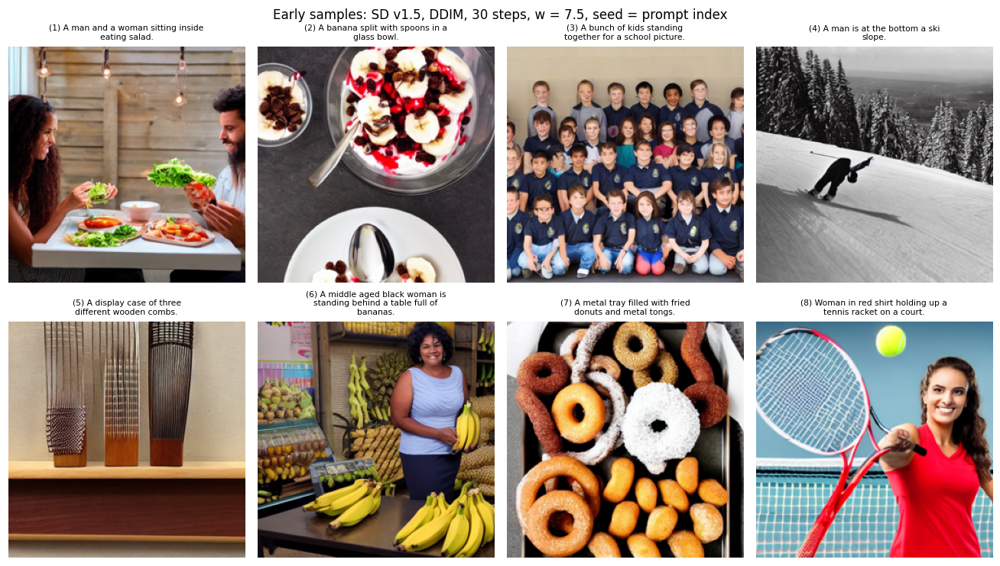

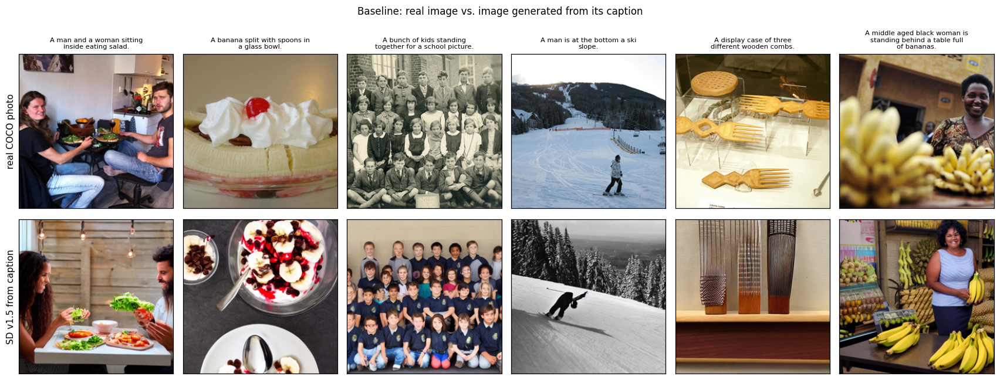

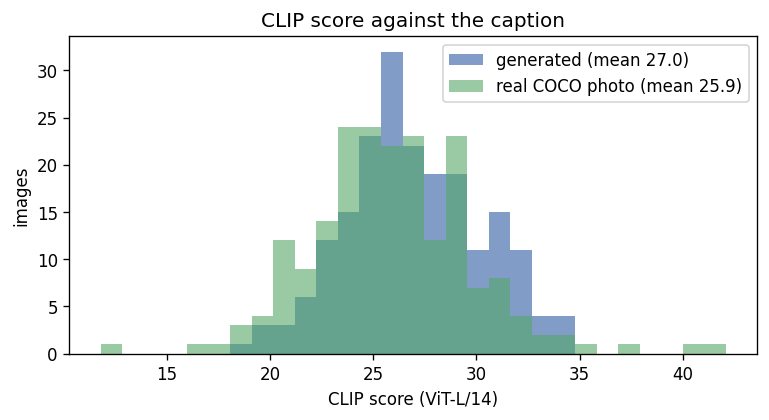

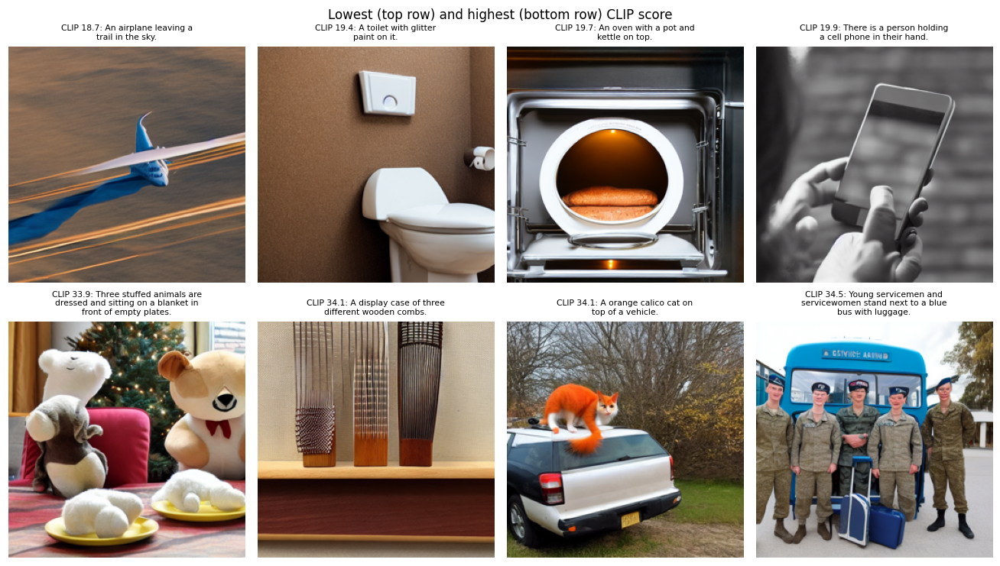

In [6]:
show('baseline_samples.png', 'baseline_gallery.png', 'baseline_clip_hist.png', 'baseline_clip_extremes.png')

## 2. Classifier-free guidance scale

The same 32 captions at w ∈ {1, 3, 5, 7.5, 10, 15}, two seeds per caption. Seed diversity is 1 − cosine similarity between the CLIP embeddings of the two images. At w = 1 there is no guidance.

In [7]:
run('02_guidance_sweep.py')

code version: e62be8d Milestone 2: noise-schedule experiment (Euler: leading, linspace, trailing, Karras) and an 8-image early-samples figure with prompts
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)

Loading pipeline components...:  33%|███▎      | 2/6 [00:10<00:20,  5.17s/it]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   1%|          | 2/196 [00:00<01:02,  3.12it/s]

Loading weights:  37%|███▋      | 72/196 [00:00<00:00, 126.24it/s]

Loading weights:  55%|█████▌    | 108/196 [00:00<00:00, 136.44it/s]

Loading weights:  69%|██████▉   | 135/196 [00:01<00:00, 150.29it/s]

Loading weights:  81%|████████  | 159/196 [00:01<00:00, 145.67it/s]

Loading weights: 100%|██████████| 196/196 [00:01<00:00, 127.76it/s]

Loading pipeline components...: 100%|

w=   1  CLIP 21.93 ± 0.99  diversity 0.280  saturation 0.212  2.546 s/img
w=   3  CLIP 25.31 ± 0.95  diversity 0.199  saturation 0.249  4.6 s/img
w=   5  CLIP 25.83 ± 1.11  diversity 0.168  saturation 0.288  4.595 s/img
w= 7.5  CLIP 26.46 ± 1.15  diversity 0.154  saturation 0.322  4.436 s/img
w=  10  CLIP 26.52 ± 1.05  diversity 0.129  saturation 0.350  4.526 s/img
w=  15  CLIP 26.88 ± 1.04  diversity 0.125  saturation 0.390  4.524 s/img


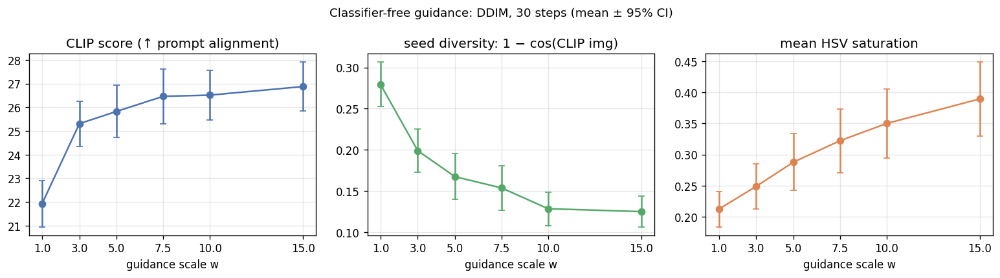

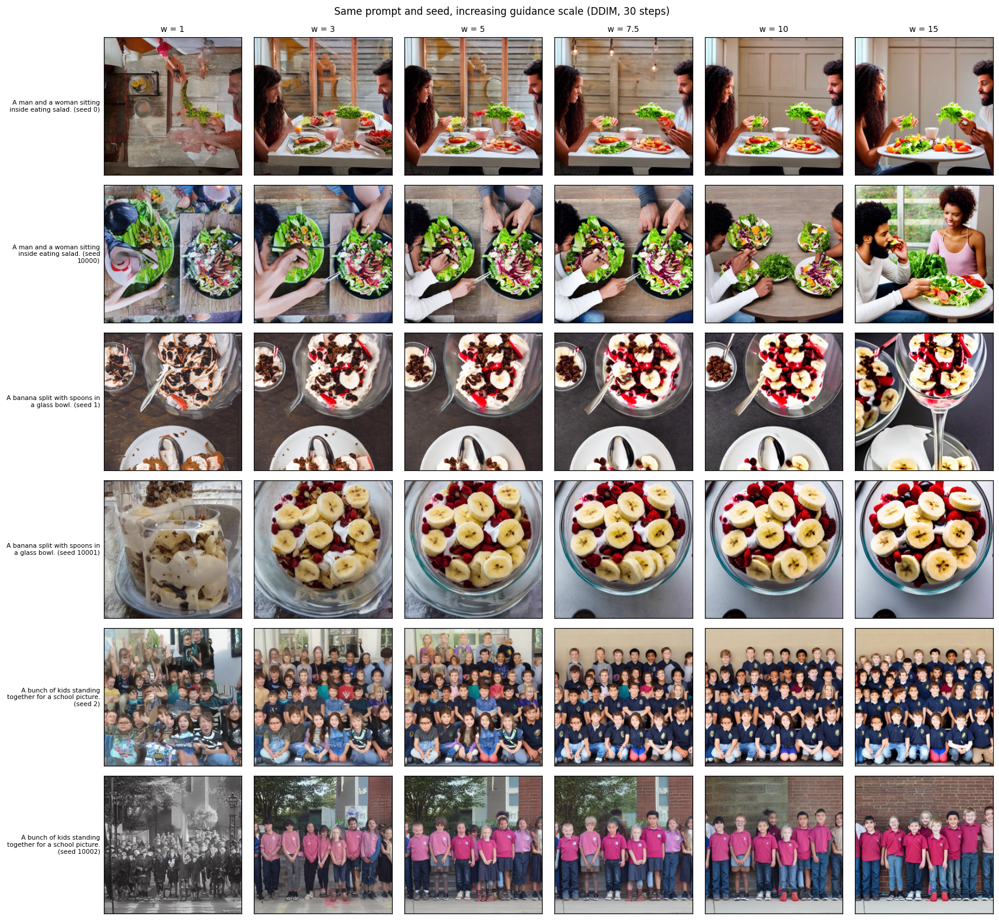

In [8]:
for s in json.load(open(OUT / 'results/guidance_sweep_summary.json'))['per_scale']:
    print(f"w={s['guidance']:>4}  CLIP {s['clip_score']:.2f} ± {s['clip_score_ci95']:.2f}  "
          f"diversity {s.get('diversity', float('nan')):.3f}  saturation {s['saturation']:.3f}  {s['seconds_per_image']} s/img")
show('guidance_curves.png', 'guidance_grid.png')

## 3. Scheduler × sampling steps

Six schedulers at 10, 25 and 50 steps with w = 7.5. Each image is also compared with the same scheduler's 50-step image.

In [9]:
run('03_scheduler_sweep.py')

code version: e62be8d Milestone 2: noise-schedule experiment (Euler: leading, linspace, trailing, Karras) and an 8-image early-samples figure with prompts
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)

Loading pipeline components...:  17%|█▋        | 1/6 [00:08<00:40,  8.13s/it]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   1%|          | 2/196 [00:00<01:24,  2.28it/s]

Loading weights:  40%|███▉      | 78/196 [00:00<00:01, 107.87it/s]

Loading weights:  62%|██████▏   | 121/196 [00:01<00:00, 114.52it/s]

Loading weights:  77%|███████▋  | 151/196 [00:01<00:00, 126.72it/s]

Loading weights:  90%|████████▉ | 176/196 [00:01<00:00, 122.03it/s]

Loading weights: 100%|██████████| 196/196 [00:01<00:00, 105.32it/s]

Loading pipeline components...: 100%|

    ddim  10 steps  CLIP 26.92 ± 1.40  Δpixel→50 33.06  1.786 s/img
    ddim  25 steps  CLIP 26.83 ± 1.48  Δpixel→50 16.12  3.62 s/img
    ddim  50 steps  CLIP 26.55 ± 1.45  Δpixel→50 0.0  7.309 s/img
    ddpm  10 steps  CLIP 26.78 ± 1.27  Δpixel→50 52.44  1.7 s/img
    ddpm  25 steps  CLIP 27.44 ± 1.19  Δpixel→50 40.79  3.809 s/img
    ddpm  50 steps  CLIP 26.59 ± 1.21  Δpixel→50 0.0  7.86 s/img
    pndm  10 steps  CLIP 25.79 ± 1.45  Δpixel→50 39.44  1.925 s/img
    pndm  25 steps  CLIP 26.98 ± 1.53  Δpixel→50 18.04  4.146 s/img
    pndm  50 steps  CLIP 26.86 ± 1.51  Δpixel→50 0.0  7.809 s/img
   euler  10 steps  CLIP 26.60 ± 1.31  Δpixel→50 25.44  1.783 s/img
   euler  25 steps  CLIP 27.25 ± 1.50  Δpixel→50 10.99  3.996 s/img
   euler  50 steps  CLIP 26.95 ± 1.68  Δpixel→50 0.0  7.652 s/img
 euler_a  10 steps  CLIP 27.12 ± 1.29  Δpixel→50 50.57  1.785 s/img
 euler_a  25 steps  CLIP 26.50 ± 1.21  Δpixel→50 39.11  3.996 s/img
 euler_a  50 steps  CLIP 26.87 ± 1.16  Δpixel→50 0.0  7.668 

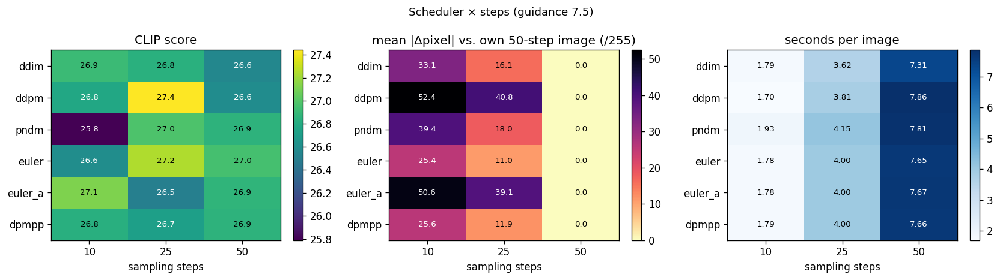

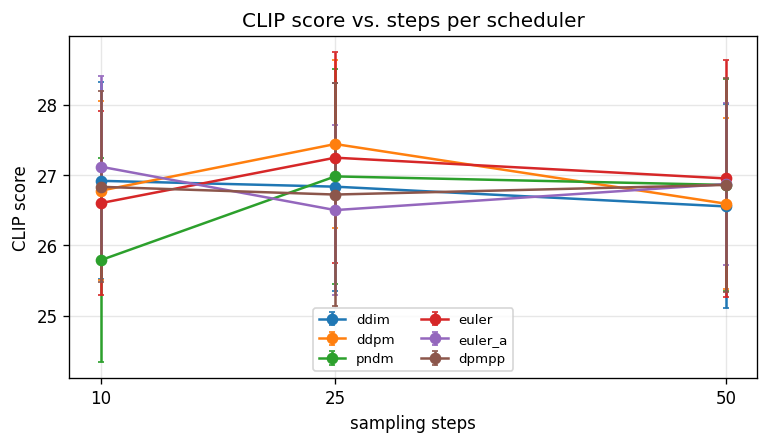

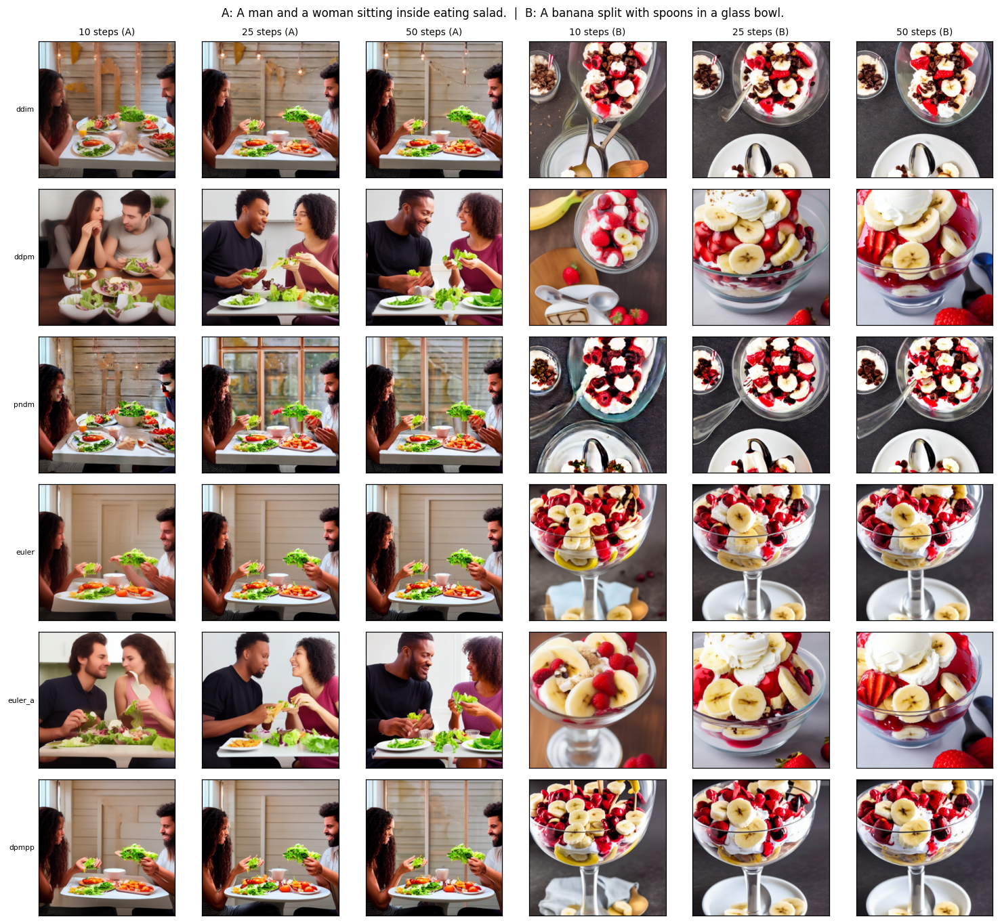

In [10]:
for s in json.load(open(OUT / 'results/scheduler_sweep_summary.json'))['per_config']:
    print(f"{s['scheduler']:>8} {s['steps']:>3} steps  CLIP {s['clip_score']:.2f} ± {s['clip_score_ci95']:.2f}  "
          f"Δpixel→50 {s['pixel_diff_to_50']}  {s['seconds_per_image']} s/img")
show('scheduler_heatmaps.png', 'scheduler_clip_vs_steps.png', 'scheduler_grid.png')

## 4. Noise schedule (Euler, w = 7.5)

The sampler is fixed and only the spacing of the noise levels changes: leading (SD v1.5 default), linspace, trailing and Karras, at 10 and 25 steps, compared with leading at 50 steps.

In [11]:
run('04_noise_schedule.py')

code version: e62be8d Milestone 2: noise-schedule experiment (Euler: leading, linspace, trailing, Karras) and an 8-image early-samples figure with prompts
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   1%|          | 2/196 [00:00<00:57,  3.35it/s]

Loading weights:  37%|███▋      | 72/196 [00:00<00:00, 126.99it/s]

Loading weights:  52%|█████▏    | 101/196 [00:00<00:00, 146.71it/s]

Loading weights:  64%|██████▍   | 126/196 [00:01<00:00, 136.57it/s]

Loading weights:  74%|███████▍  | 146/196 [00:01<00:00, 144.91it/s]

Loading weights:  84%|████████▍ | 165/196 [00:01<00:00, 150.04it/s]

Loading weights: 100%|██████████| 196/196 [00

 leading  50 steps  CLIP 26.74 ± 1.48  Δpixel→ref 0.0  first σ None  7.695 s/img
 leading  10 steps  CLIP 26.98 ± 1.44  Δpixel→ref 33.1  first σ 8.3907  1.783 s/img
 leading  25 steps  CLIP 26.91 ± 1.49  Δpixel→ref 16.24  first σ 11.6761  3.997 s/img
linspace  10 steps  CLIP 26.60 ± 1.31  Δpixel→ref 26.12  first σ 14.6146  1.786 s/img
linspace  25 steps  CLIP 27.25 ± 1.50  Δpixel→ref 17.89  first σ 14.6146  3.989 s/img
trailing  10 steps  CLIP 26.92 ± 1.43  Δpixel→ref 25.71  first σ 14.6146  1.786 s/img
trailing  25 steps  CLIP 27.30 ± 1.52  Δpixel→ref 17.61  first σ 14.6146  3.988 s/img
  karras  10 steps  CLIP 26.73 ± 1.45  Δpixel→ref 32.79  first σ 8.3907  1.786 s/img
  karras  25 steps  CLIP 26.65 ± 1.41  Δpixel→ref 15.61  first σ 11.6761  3.99 s/img


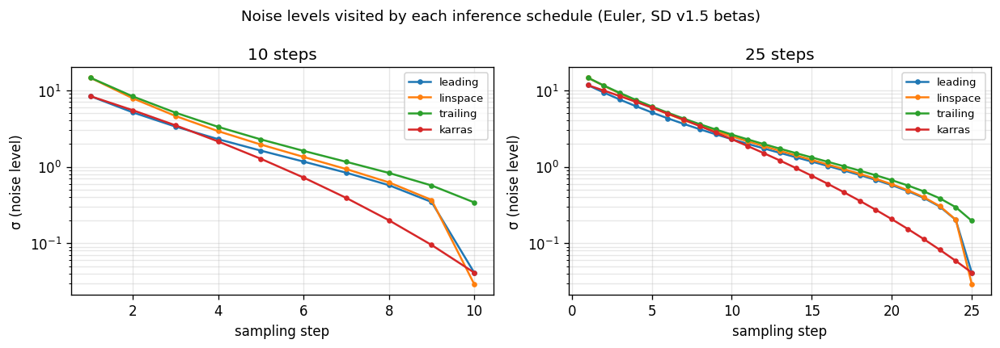

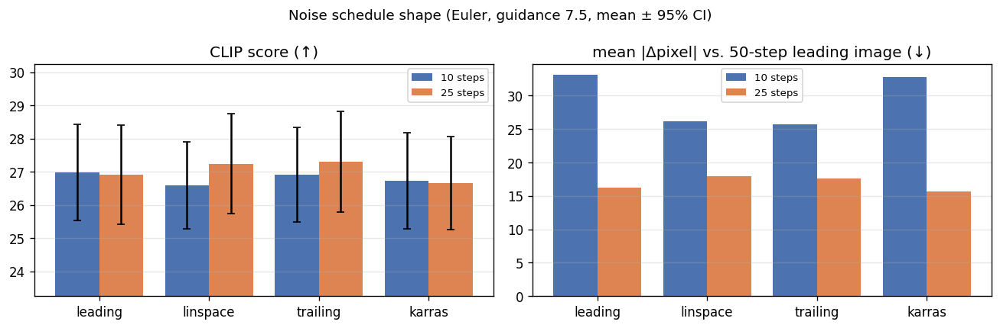

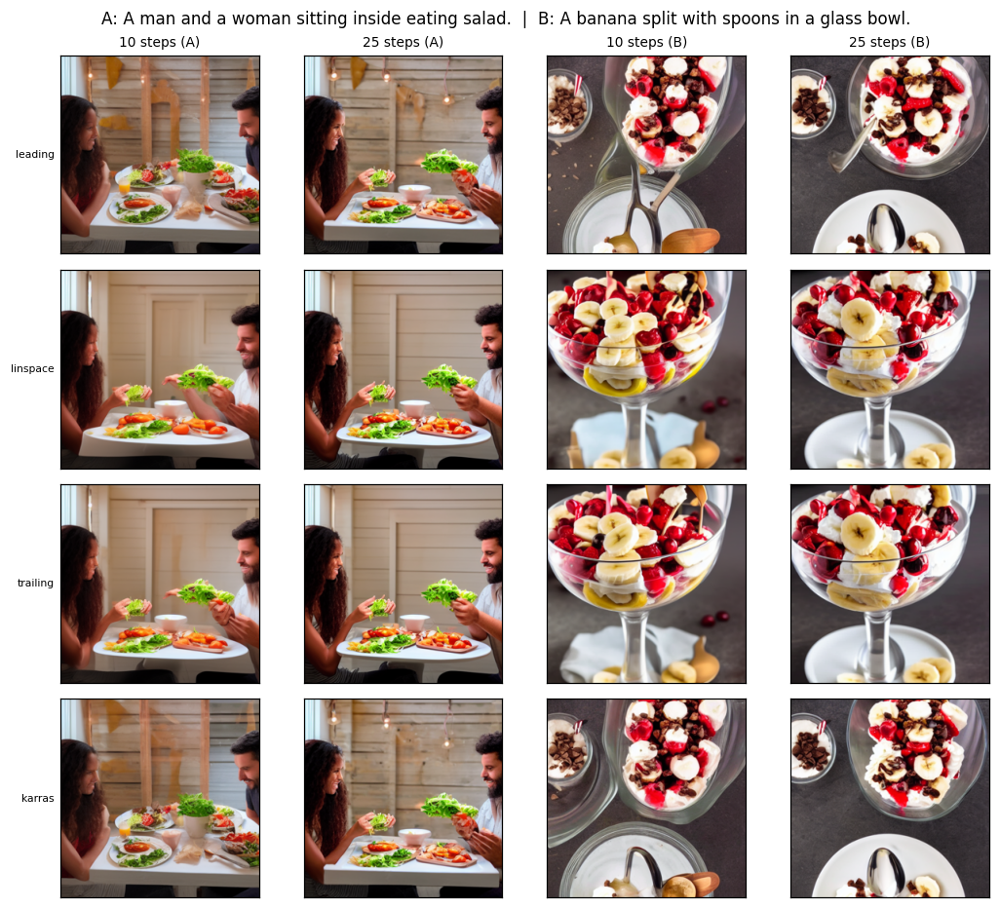

In [12]:
for s in json.load(open(OUT / 'results/noise_schedule_summary.json'))['per_config']:
    print(f"{s['schedule']:>8} {s['steps']:>3} steps  CLIP {s['clip_score']:.2f} ± {s['clip_score_ci95']:.2f}  "
          f"Δpixel→ref {s['pixel_diff_to_ref']}  first σ {s['first_sigma']}  {s['seconds_per_image']} s/img")
show('noise_schedule_sigmas.png', 'noise_schedule_metrics.png', 'noise_schedule_grid.png')